<a href="https://colab.research.google.com/github/Annette-1/SIMULACION-II/blob/main/Procesos_Derivados_MB_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# <span style="color:magenta;">**Movimiento Browniano**</span>

<span style="color:teal;">**Nombre:** </span> Jerónimo López Annette Michelle

<span style="color:teal;"> **Objetivo:**</span> Modelar matemáticamente fenómenos aleatorios continuos que presentan fluctuaciones impredecibles pero con estructura estadística conocida.

**Simulación:** Moivimiento Browviano
Dado $[0,T]$ sea $δt=\frac{T}{L}$, para algún positivo $L$.
Sea $ w_i$ que denote $w(t_i)$ en $t_i=iδt$.

<span style="color:orange;">

*Seudocódigo:*

1. $δt= \frac{T}{L}$
2. $w_0=0$
3. Para $i=0$ a $L-1$:
4.    Calcule un $\xi∼N(0,1)$

5. $w_{i+1}=w_i + \sqrt{δt}\xi_i$
6. Terminar
</span>

<span style="color:purple;">**Actividad**</span>

1. Programar el Seudocódigo y graficar una trayectoria para $T=1$ y $L=10$.

2. Graficar en el mismo panel $100$ trayectorias junto con $f(t)=\sqrt{t}$, $g(t)=-\sqrt{t}$

3. Comentarios y conclusiones.


Para el inciso 1. Generamos 100 trayectorias con T=1, L=100 pasos

In [78]:
import numpy as np
import matplotlib.pyplot as plt

In [79]:
def simular_browniano(T=1, L=100):
    """
    Simula una trayectoria de movimiento browniano.

    Parámetros:
        T: tiempo final
        L: número de intervalos

    Retorna:
        t: vector de tiempos
        W: trayectoria browniana
    """
    dt = T / L
    t = np.linspace(0, T, L + 1)

    W = np.zeros(L + 1)

    for i in range(L):
        xi = np.random.normal(0, 1)
        W[i + 1] = W[i] + np.sqrt(dt) * xi

    return t, W

In [80]:
def graficar_trayectoria(T=1, L=100):
    t, W = simular_browniano(T, L)

    plt.figure(figsize=(8, 5))
    plt.plot(t, W, lw=2)

    plt.title("Una trayectoria de Movimiento Browniano")
    plt.xlabel("t")
    plt.ylabel("W(t)")
    plt.grid(True)
    plt.show()

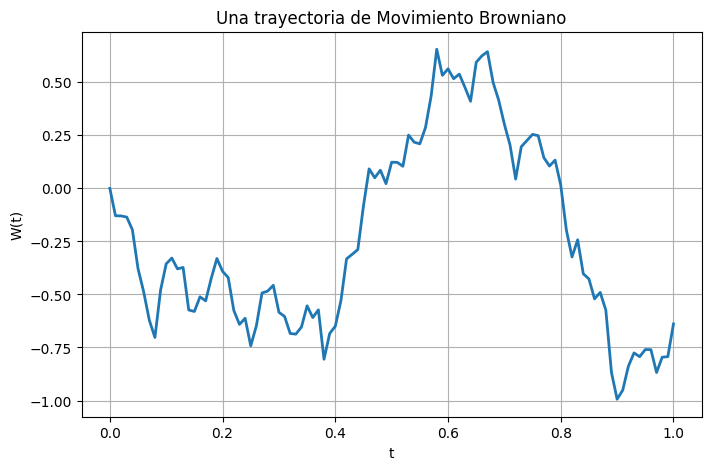

In [81]:
graficar_trayectoria()

In [82]:
def graficar_multiples_brownianos(T=1, L=100, N=100):
    """
    Grafica N trayectorias de movimiento browniano
    junto con la función f(t) = sqrt(t).
    """
    dt = T / L
    t = np.linspace(0, T, L + 1)

    # Generar incrementos gaussianos
    dW = np.sqrt(dt) * np.random.randn(N, L)

    # Construir las trayectorias
    W = np.cumsum(dW, axis=1)

    # Agregar W(0) = 0
    W = np.column_stack((np.zeros(N), W))

    plt.figure(figsize=(10, 6))

    for k in range(N):
        plt.plot(t, W[k], alpha=0.3)

    # Curva de referencia
    plt.plot(t, np.sqrt(t), 'k', lw=3, label=r'$\sqrt{t}$')
    plt.plot(t, -np.sqrt(t), 'k--', lw=2, label=r'$-\sqrt{t}$')

    plt.title(f"{N} trayectorias de Movimiento Browniano")
    plt.xlabel("t")
    plt.ylabel("W(t)")
    plt.legend()
    plt.grid(True)
    plt.show()

    return t, W

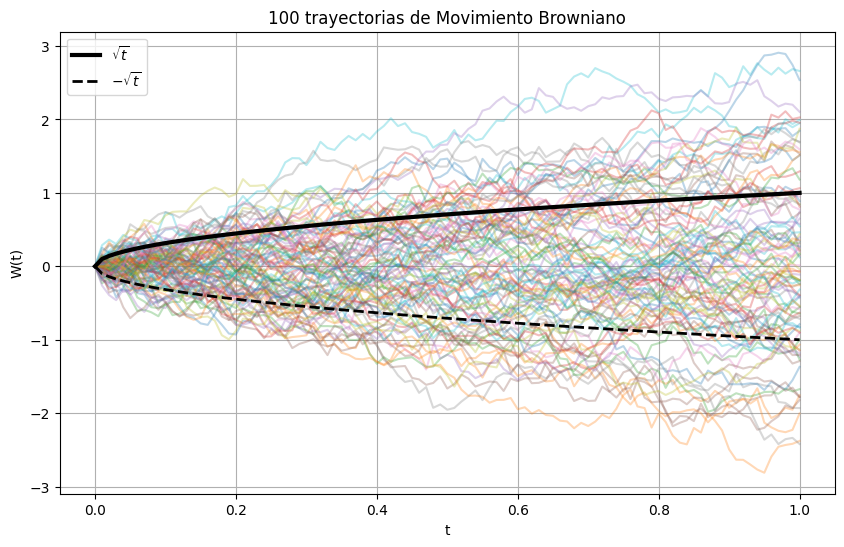

In [83]:
t, W = graficar_multiples_brownianos(T=1, L=100, N=100)

In [84]:
def refinar_browniano(t_original, W_original):
    """
    Refina una trayectoria de movimiento browniano
    insertando un punto intermedio en cada intervalo.

    Parámetros:
        t_original: tiempos originales
        W_original: valores originales del browniano

    Retorna:
        t_refined: tiempos refinados
        W_refined: trayectoria refinada
    """
    L = len(t_original) - 1

    t_refined = np.zeros(2 * L + 1)
    W_refined = np.zeros(2 * L + 1)

    # Conservar los puntos originales
    t_refined[::2] = t_original
    W_refined[::2] = W_original

    for i in range(L):
        dt = t_original[i + 1] - t_original[i]

        # Tiempo intermedio
        t_refined[2 * i + 1] = (
            t_original[i] + t_original[i + 1]
        ) / 2

        # Variable normal independiente
        xi = np.random.normal(0, 1)

        # Punto intermedio del puente browniano
        W_refined[2 * i + 1] = (
            (W_original[i] + W_original[i + 1]) / 2
            + 0.5 * np.sqrt(dt) * xi
        )

    return t_refined, W_refined

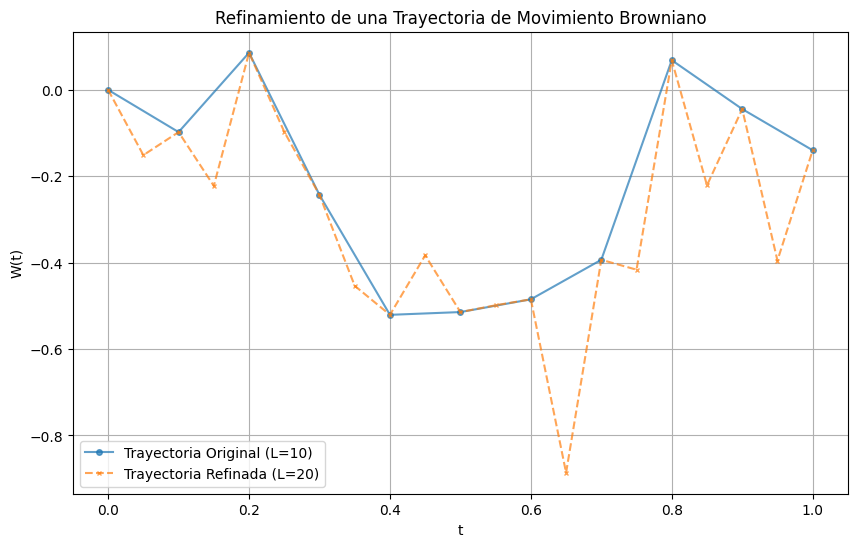

In [85]:
# Calcular el número de intervalos de la trayectoria refinada
L_refined = len(t_refined) - 1

# Graficar la trayectoria original y la refinada
plt.figure(figsize=(10, 6))
plt.plot(t_original, W_original, 'o-', label='Trayectoria Original (L=10)', alpha=0.7, markersize=4)
plt.plot(t_refined, W_refined, 'x--', label=f'Trayectoria Refinada (L={L_refined})', alpha=0.7, markersize=3)
plt.title('Refinamiento de una Trayectoria de Movimiento Browniano')
plt.xlabel('t')
plt.ylabel('W(t)')
plt.legend()
plt.grid(True)
plt.show()

* <span style="color:blue;">**Puente Browviano**</span>

Es el proceso

$$
X_{t}=B_t -tB_1 \quad , \quad 0 ≤t≤1
$$

Obviamente
$$X_0=0 \quad , \quad X_1=0 \quad E(X_t)= cov(X_t,X_s)$$

* <span style="color:blue;">**Movimiento Browviano deriva** </span>
$$
X_t= \mu t + σB_t \quad , \quad t \geq0
$$
 para $$\mu ϵ R \quad y \quad σ>0$$

 $$E(X_t)= cov(X_t,X_s)$$

 * <span style="color:blue;">**Movimiento Browviano Geómetrico**</span>

 $$
X_{t}=e ^{\mu t + σB_t} \quad , \quad  t \geq0
$$

Agregamos el Puente Browviano definido como:

$$
X_{t}=B_t -tB_1 \quad , \quad 0 ≤t≤1
$$

Obviamente
$$X_0=0 \quad , \quad X_1=0 \quad E(X_t)= cov(X_t,X_s)$$

In [86]:
def simular_puente_browniano(N=100, L=100):
    """
    Simula N trayectorias de un puente browniano en [0, 1].

    Retorna:
        t: vector de tiempos
        X: matriz de trayectorias del puente browniano
    """
    T = 1

    t, W = simular_browniano(T, L, N)

    X = W - t * W[:, -1].reshape(-1, 1)

    return t, X

In [87]:
def esperanza_puente(t):
    """Esperanza teórica del puente browniano."""
    return np.zeros_like(np.asarray(t, dtype=float))


def varianza_puente(t):
    """Varianza teórica del puente browniano."""
    t = np.asarray(t, dtype=float)
    return t * (1 - t)


def covarianza_puente(t, s):
    """Covarianza teórica entre X_t y X_s."""
    return min(t, s) - t * s

In [88]:
def simular_browniano_deriva(mu=0.5, sigma=1.0,
                             T=1, L=100, N=100):
    """
    Simula N trayectorias de movimiento browniano con deriva.

    Retorna:
        t: vector de tiempos
        X: matriz de trayectorias
    """
    t, W = simular_browniano(T, L, N)

    X = mu * t + sigma * W

    return t, X

In [89]:
def esperanza_deriva(t, mu):
    """Esperanza teórica."""
    return mu * np.asarray(t)


def varianza_deriva(t, sigma):
    """Varianza teórica."""
    return sigma**2 * np.asarray(t)


def covarianza_deriva(t, s, sigma):
    """Covarianza teórica."""
    return sigma**2 * min(t, s)

In [90]:
def simular_browniano_geometrico(mu=0.3, sigma=0.5,
                                 T=1, L=100, N=100):
    """
    Simula N trayectorias de movimiento browniano geométrico
    según X_t = exp(mu*t + sigma*W_t).

    Retorna:
        t: vector de tiempos
        X: matriz de trayectorias
    """
    t, W = simular_browniano(T, L, N)

    X = np.exp(mu * t + sigma * W)

    return t, X

In [91]:
def esperanza_geometrico(t, mu, sigma):
    """Esperanza teórica del movimiento browniano geométrico."""
    t = np.asarray(t)
    return np.exp((mu + sigma**2 / 2) * t)


def varianza_geometrico(t, mu, sigma):
    """Varianza teórica del movimiento browniano geométrico."""
    t = np.asarray(t)
    return (
        np.exp((2 * mu + sigma**2) * t)
        * (np.exp(sigma**2 * t) - 1)
    )


def covarianza_geometrico(t, s, mu, sigma):
    """Covarianza teórica entre X_t y X_s."""
    return (
        np.exp(mu * (t + s) + (sigma**2 / 2) * (t + s))
        * (np.exp(sigma**2 * min(t, s)) - 1)
    )

In [92]:
def esperanza_simulada(X):
    """
    Calcula la esperanza empírica en cada instante.
    X tiene dimensiones (N, L+1).
    """
    return np.mean(X, axis=0)


def varianza_simulada(X):
    """
    Calcula la varianza empírica en cada instante.
    """
    return np.var(X, axis=0)


def covarianza_simulada(X, i, j):
    """
    Calcula la covarianza empírica entre los tiempos
    correspondientes a las columnas i y j de X.
    """
    return np.cov(X[:, i], X[:, j], ddof=0)[0, 1]

In [93]:
def comparar_estadisticas_finales(X, T, esperanza_teorica,
                                  varianza_teorica):
    """
    Compara esperanza y varianza teóricas y simuladas
    en el tiempo final T.

    esperanza_teorica y varianza_teorica deben ser
    valores numéricos correspondientes al tiempo T.
    """
    media_sim = np.mean(X[:, -1])
    var_sim = np.var(X[:, -1])

    print("=== COMPARACIÓN TEÓRICA VS. SIMULADA ===")
    print(f"Tiempo final T = {T}")
    print(f"Esperanza teórica: {esperanza_teorica:.6f}")
    print(f"Esperanza simulada: {media_sim:.6f}")
    print(f"Varianza teórica: {varianza_teorica:.6f}")
    print(f"Varianza simulada: {var_sim:.6f}")

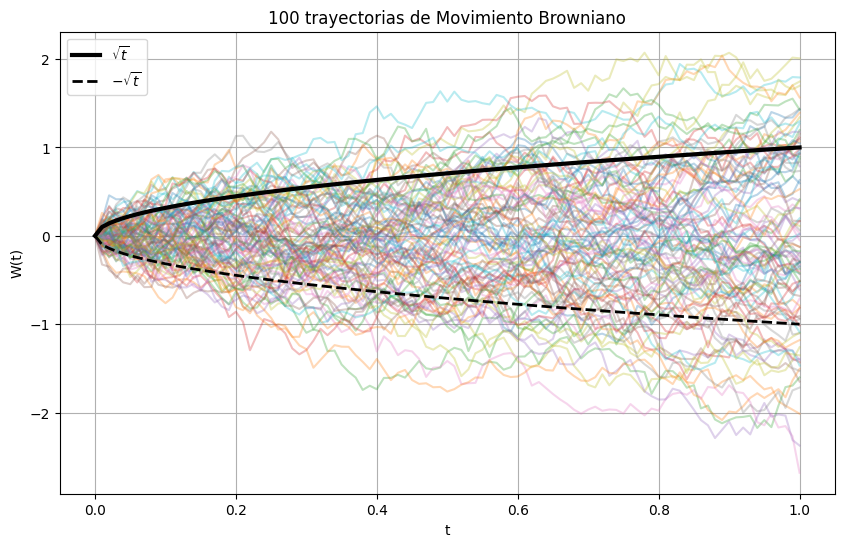

=== PUENTE BROWNIANO ===
Esperanza teórica en t=0.5: 0.0
Esperanza simulada en t=0.5: -0.031915931522274246
Varianza teórica en t=0.5: 0.25
Varianza simulada en t=0.5: 0.2449513649207922
Covarianza teórica (0.3, 0.7): 0.09
Covarianza simulada (0.3, 0.7): 0.08002095681569013

=== COMPARACIÓN TEÓRICA VS. SIMULADA ===
Tiempo final T = 1
Esperanza teórica: 0.500000
Esperanza simulada: 0.458364
Varianza teórica: 1.000000
Varianza simulada: 1.045919

=== COMPARACIÓN TEÓRICA VS. SIMULADA ===
Tiempo final T = 1
Esperanza teórica: 1.529590
Esperanza simulada: 1.500137
Varianza teórica: 0.664519
Varianza simulada: 0.563598


In [95]:
# Parámetros
T = 1
L = 100
N = 100

# Usamos la función que sí genera múltiples trayectorias de tamaño (N, L+1)
t_pb, W_multiples = graficar_multiples_brownianos(T=T, L=L, N=N)

# 1. Puente browniano
# X_t = W_t - t * W_1
X_pb = W_multiples - t_pb * W_multiples[:, -1].reshape(-1, 1)

print("=== PUENTE BROWNIANO ===")
print("Esperanza teórica en t=0.5:", esperanza_puente(0.5))
print("Esperanza simulada en t=0.5:", np.mean(X_pb[:, L//2]))
print("Varianza teórica en t=0.5:", varianza_puente(0.5))
print("Varianza simulada en t=0.5:", np.var(X_pb[:, L//2]))
print("Covarianza teórica (0.3, 0.7):", covarianza_puente(0.3, 0.7))
print("Covarianza simulada (0.3, 0.7):", covarianza_simulada(X_pb, int(0.3*L), int(0.7*L)))
print()

# 2. Browniano con deriva
mu_d = 0.5
sigma_d = 1.0
X_d = mu_d * t_pb + sigma_d * W_multiples

comparar_estadisticas_finales(
    X_d, T,
    esperanza_deriva(T, mu_d),
    varianza_deriva(T, sigma_d)
)

print()

# 3. Browniano geométrico
mu_g = 0.3
sigma_g = 0.5
X_g = np.exp(mu_g * t_pb + sigma_g * W_multiples)

comparar_estadisticas_finales(
    X_g, T,
    esperanza_geometrico(T, mu_g, sigma_g),
    varianza_geometrico(T, mu_g, sigma_g)
)